In [1]:
import pandas as pd

prices = pd.read_excel("Historical Data Apple.xlsx")

prices.head()

,Date,Close,High,Low,Open,Adj Close,Volume,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11
0,2020-01-02,75.087502,75.150002,73.797501,74.059998,72.216675,135480400,NaN,NaN,NaN,NaN,NaN
1,2020-01-03,74.357498,75.144997,74.125000,74.287498,71.514595,146322800,NaN,NaN,NaN,NaN,NaN
2,2020-01-06,74.949997,74.989998,73.187500,73.447502,72.084412,118387200,NaN,NaN,NaN,NaN,NaN
3,2020-01-07,74.597504,75.224998,74.370003,74.959999,71.745445,108872000,NaN,NaN,NaN,NaN,NaN
4,2020-01-08,75.797501,76.110001,74.290001,74.290001,72.899536,132079200,NaN,NaN,NaN,NaN,\


In [2]:
prices = pd.read_excel(
    "Historical Data Apple.xlsx",
    usecols="A:G"
)

prices.head()

,Date,Close,High,Low,Open,Adj Close,Volume
0,2020-01-02,75.087502,75.150002,73.797501,74.059998,72.216675,135480400
1,2020-01-03,74.357498,75.144997,74.125000,74.287498,71.514595,146322800
2,2020-01-06,74.949997,74.989998,73.187500,73.447502,72.084412,118387200
3,2020-01-07,74.597504,75.224998,74.370003,74.959999,71.745445,108872000
4,2020-01-08,75.797501,76.110001,74.290001,74.290001,72.899536,132079200


In [3]:
prices.info()

<class 'pandas.DataFrame'>
RangeIndex: 1729 entries, 0 to 1728
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       1729 non-null   datetime64[us]
 1   Close      1729 non-null   float64       
 2   High       1729 non-null   float64       
 3   Low        1729 non-null   float64       
 4   Open       1729 non-null   float64       
 5   Adj Close  1729 non-null   float64       
 6   Volume     1729 non-null   int64         
dtypes: datetime64[us](1), float64(5), int64(1)
memory usage: 94.7 KB


In [4]:
print("Missing values by column:")
print(prices.isna().sum())

print("Duplicate rows:", prices.duplicated().sum())

Missing values by column:
Date         0
Close        0
High         0
Low          0
Open         0
Adj Close    0
Volume       0
dtype: int64
Duplicate rows: 0


In [5]:
if "Adj Close" in prices.columns:
    price_column = "Adj Close"
else:
    price_column = "Close"

prices["Daily Return"] = prices[price_column].pct_change()

prices[["Date", price_column, "Daily Return"]].head()

,Date,Adj Close,Daily Return
0,2020-01-02,72.216675,NaN
1,2020-01-03,71.514595,-0.009722
2,2020-01-06,72.084412,0.007968
3,2020-01-07,71.745445,-0.004702
4,2020-01-08,72.899536,0.016086


In [6]:
prices["Daily Return Percent"] = prices["Daily Return"] * 100

prices[["Date", "Daily Return Percent"]].head()

,Date,Daily Return Percent
0,2020-01-02,NaN
1,2020-01-03,-0.972185
2,2020-01-06,0.796784
3,2020-01-07,-0.470235
4,2020-01-08,1.608591


In [7]:
average_daily_return = prices["Daily Return"].mean()
daily_volatility = prices["Daily Return"].std()

annualized_volatility = daily_volatility * (252 ** 0.5)

print("Average daily return:", round(average_daily_return * 100, 3), "%")
print("Annualized volatility:", round(annualized_volatility * 100, 2), "%")

Average daily return: 0.111 %
Annualized volatility: 31.13 %


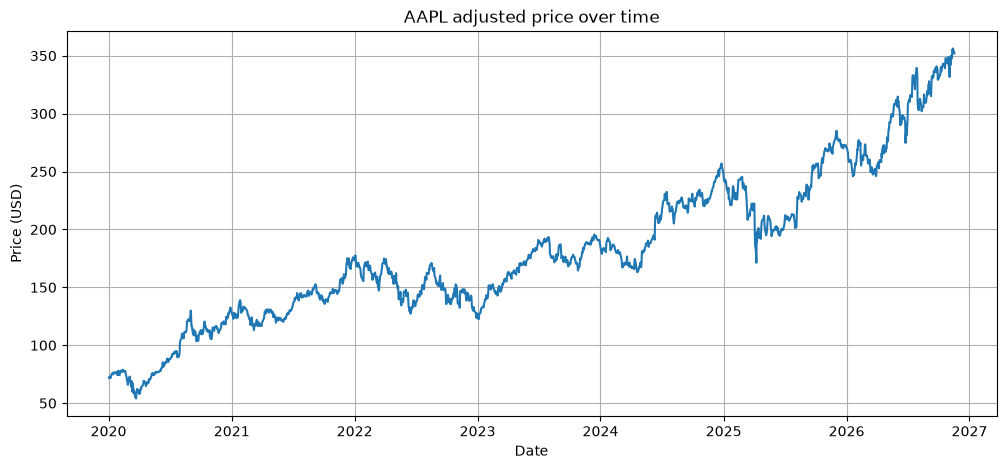

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(prices["Date"], prices[price_column])
plt.title("AAPL adjusted price over time")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.grid(True)
plt.show()

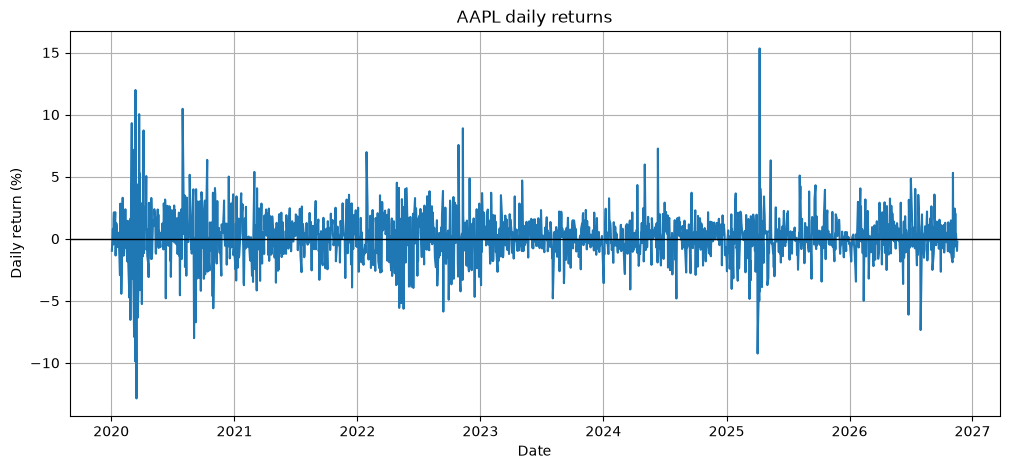

In [9]:
plt.figure(figsize=(12, 5))
plt.plot(prices["Date"], prices["Daily Return"] * 100)
plt.title("AAPL daily returns")
plt.xlabel("Date")
plt.ylabel("Daily return (%)")
plt.axhline(0, color="black", linewidth=1)
plt.grid(True)
plt.show()

In [10]:
best_day = prices.loc[prices["Daily Return"].idxmax()]
worst_day = prices.loc[prices["Daily Return"].idxmin()]

print("Data period:", prices["Date"].min().date(), "to", prices["Date"].max().date())
print("Largest increase:", best_day["Date"].date(),
      round(best_day["Daily Return"] * 100, 2), "%")
print("Largest decrease:", worst_day["Date"].date(),
      round(worst_day["Daily Return"] * 100, 2), "%")

Data period: 2020-01-02 to 2026-11-17
Largest increase: 2025-04-09 15.33 %
Largest decrease: 2020-03-16 -12.86 %


In [11]:
prices.loc[
    prices["Date"].isin(pd.to_datetime(["2025-04-09", "2020-03-16"])),
    ["Date", "Open", "High", "Low", "Close", "Adj Close", "Volume", "Daily Return"]
]

,Date,Open,High,Low,Close,Adj Close,Volume,Daily Return
50,2020-03-16,60.487499,64.769997,60.000000,60.552502,58.375618,322423600,-0.128647
1324,2025-04-09,171.949997,200.610001,171.889999,198.850006,197.484344,184395900,0.153289


In [12]:
import yfinance as yf

spy = yf.download(
    "SPY",
    start="2020-01-02",
    end="2026-11-18",
    interval="1d",
    auto_adjust=False,
    multi_level_index=False,
    progress=False
)

spy = spy.reset_index()

print(spy.columns.tolist())
spy.head()

['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


,Date,Adj Close,Close,High,Low,Open,Volume
0,2020-01-02,295.391785,324.869995,324.890015,322.529999,323.540009,59151200
1,2020-01-03,293.154999,322.410004,323.640015,321.100006,321.160004,77709700
2,2020-01-06,294.273438,323.640015,323.730011,320.359985,320.489990,55653900
3,2020-01-07,293.445892,322.730011,323.540009,322.239990,323.019989,40496400
4,2020-01-08,295.009888,324.450012,325.779999,322.670013,322.940002,68296000


In [13]:
spy.to_csv("SPY.csv", index=False)

In [14]:
spy.to_csv("SPY.csv", index=False)

In [15]:
import yfinance as yf

spy = yf.download(
    "SPY",
    start="2020-01-02",
    end="2026-11-18",
    interval="1d",
    auto_adjust=False,
    multi_level_index=False,
    progress=False
)

spy = spy.reset_index()

print(spy.columns.tolist())
spy.head()

['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


,Date,Adj Close,Close,High,Low,Open,Volume
0,2020-01-02,295.391785,324.869995,324.890015,322.529999,323.540009,59151200
1,2020-01-03,293.154999,322.410004,323.640015,321.100006,321.160004,77709700
2,2020-01-06,294.273438,323.640015,323.730011,320.359985,320.489990,55653900
3,2020-01-07,293.445892,322.730011,323.540009,322.239990,323.019989,40496400
4,2020-01-08,295.009888,324.450012,325.779999,322.670013,322.940002,68296000


In [19]:
preview = pd.read_excel(
    "Historical Data Apple.xlsx",
    header=None,
    nrows=6
)

preview

,0,1,2,3,4,5,6,7,8,9,10,11
0,Date,Close,High,Low,Open,Adj Close,Volume,NaN,NaN,NaN,NaN,NaN
1,2020-01-02 00:00:00,75.087502,75.150002,73.797501,74.059998,72.216675,135480400,NaN,NaN,NaN,NaN,NaN
2,2020-01-03 00:00:00,74.357498,75.144997,74.125,74.287498,71.514595,146322800,NaN,NaN,NaN,NaN,NaN
3,2020-01-06 00:00:00,74.949997,74.989998,73.1875,73.447502,72.084412,118387200,NaN,NaN,NaN,NaN,NaN
4,2020-01-07 00:00:00,74.597504,75.224998,74.370003,74.959999,71.745445,108872000,NaN,NaN,NaN,NaN,NaN
5,2020-01-08 00:00:00,75.797501,76.110001,74.290001,74.290001,72.899536,132079200,NaN,NaN,NaN,NaN,\


In [21]:
prices = pd.read_excel(
    "Historical Data Apple.xlsx",
    usecols="A:G"
)

prices.head()

,Date,Close,High,Low,Open,Adj Close,Volume
0,2020-01-02,75.087502,75.150002,73.797501,74.059998,72.216675,135480400
1,2020-01-03,74.357498,75.144997,74.125000,74.287498,71.514595,146322800
2,2020-01-06,74.949997,74.989998,73.187500,73.447502,72.084412,118387200
3,2020-01-07,74.597504,75.224998,74.370003,74.959999,71.745445,108872000
4,2020-01-08,75.797501,76.110001,74.290001,74.290001,72.899536,132079200


In [22]:
import pandas as pd
import yfinance as yf

# Load AAPL; the first row already contains the column names
prices = pd.read_excel(
    "Historical Data Apple.xlsx",
    usecols="A:G"
)
prices.columns = prices.columns.astype(str).str.strip()
prices["Date"] = pd.to_datetime(prices["Date"]).dt.normalize()
prices = prices.sort_values("Date").reset_index(drop=True)

# Download SPY
spy = yf.download(
    "SPY",
    start="2020-01-02",
    end="2026-11-18",
    interval="1d",
    auto_adjust=False,
    multi_level_index=False,
    progress=False
).reset_index()
spy["Date"] = pd.to_datetime(spy["Date"]).dt.normalize()

# Match both datasets by date
aapl_prices = prices[["Date", "Adj Close"]].rename(
    columns={"Adj Close": "AAPL"}
)
spy_prices = spy[["Date", "Adj Close"]].rename(
    columns={"Adj Close": "SPY"}
)

comparison = aapl_prices.merge(spy_prices, on="Date", how="inner")
comparison = comparison.sort_values("Date").reset_index(drop=True)

print("Matched trading days:", len(comparison))
print("Date range:", comparison["Date"].min().date(), "to",
      comparison["Date"].max().date())
comparison.head()

Matched trading days: 1729
Date range: 2020-01-02 to 2026-11-17


,Date,AAPL,SPY
0,2020-01-02,72.216675,295.391785
1,2020-01-03,71.514595,293.154999
2,2020-01-06,72.084412,294.273438
3,2020-01-07,71.745445,293.445892
4,2020-01-08,72.899536,295.009888


In [23]:
# Compare both assets starting at the same value
comparison["AAPL Growth of $100"] = (
    comparison["AAPL"] / comparison["AAPL"].iloc[0] * 100
)
comparison["SPY Growth of $100"] = (
    comparison["SPY"] / comparison["SPY"].iloc[0] * 100
)

# Calculate the total change over the full shared period
aapl_total_return = (
    comparison["AAPL"].iloc[-1] / comparison["AAPL"].iloc[0] - 1
) * 100

spy_total_return = (
    comparison["SPY"].iloc[-1] / comparison["SPY"].iloc[0] - 1
) * 100

print("AAPL total adjusted-price return:", round(aapl_total_return, 2), "%")
print("SPY total adjusted-price return:", round(spy_total_return, 2), "%")
print(
    "AAPL minus SPY:",
    round(aapl_total_return - spy_total_return, 2),
    "percentage points"
)

AAPL total adjusted-price return: 387.3 %
SPY total adjusted-price return: 147.96 %
AAPL minus SPY: 239.34 percentage points


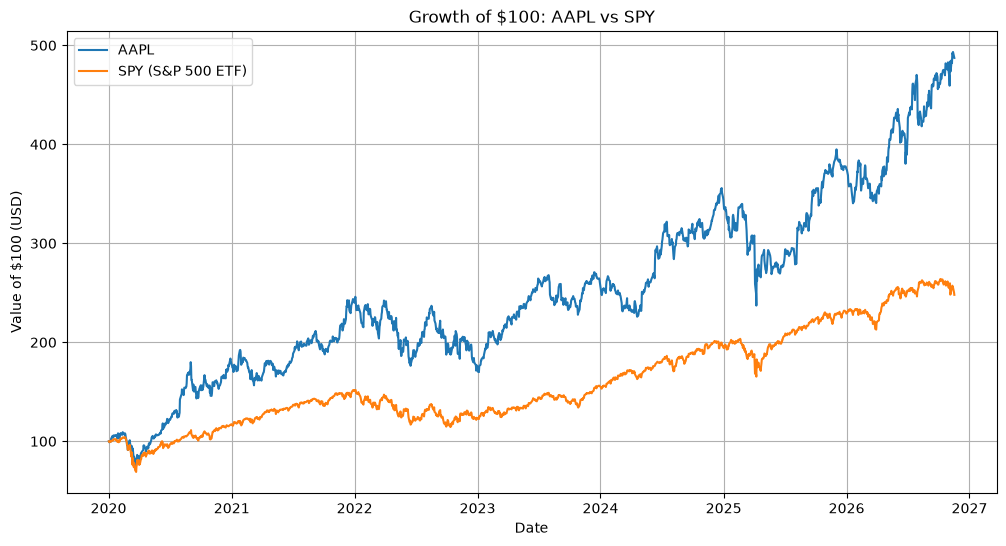

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(
    comparison["Date"],
    comparison["AAPL Growth of $100"],
    label="AAPL"
)
plt.plot(
    comparison["Date"],
    comparison["SPY Growth of $100"],
    label="SPY (S&P 500 ETF)"
)

plt.title("Growth of $100: AAPL vs SPY")
plt.xlabel("Date")
plt.ylabel("Value of $100 (USD)")
plt.legend()
plt.grid(True)
plt.show()

In [25]:
# Calculate daily returns from adjusted closing prices
daily_returns = comparison[["AAPL", "SPY"]].pct_change().dropna()

# Calculate each asset's fall from its previous peak
aapl_drawdown = comparison["AAPL"] / comparison["AAPL"].cummax() - 1
spy_drawdown = comparison["SPY"] / comparison["SPY"].cummax() - 1

# Summarize the two risk measures
risk_summary = pd.DataFrame({
    "Annualized volatility (%)": [
        daily_returns["AAPL"].std() * (252 ** 0.5) * 100,
        daily_returns["SPY"].std() * (252 ** 0.5) * 100
    ],
    "Maximum drawdown (%)": [
        aapl_drawdown.min() * 100,
        spy_drawdown.min() * 100
    ]
}, index=["AAPL", "SPY"])

risk_summary.round(2)

,Annualized volatility (%),Maximum drawdown (%)
AAPL,31.13,-33.36
SPY,20.02,-33.72


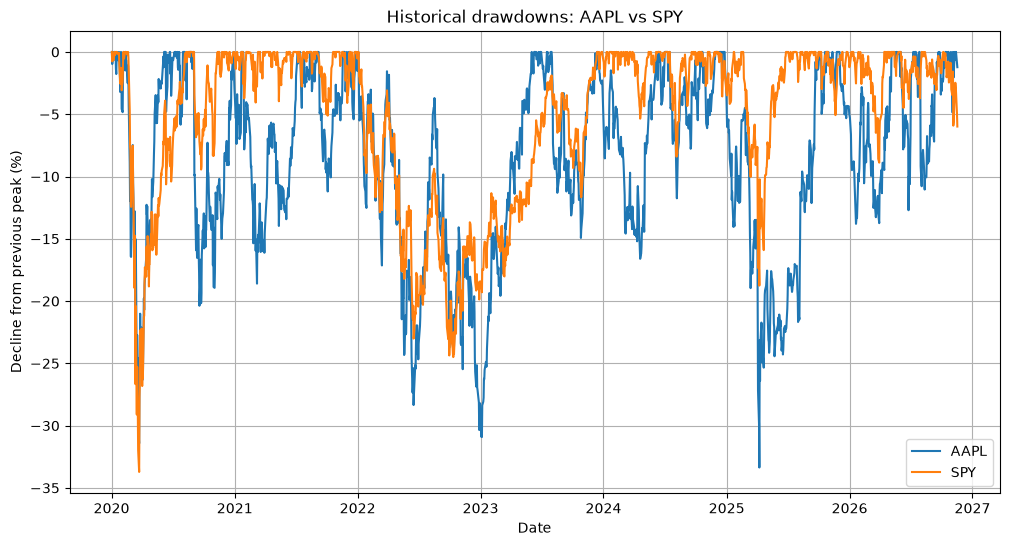

In [26]:
plt.figure(figsize=(12, 6))
plt.plot(comparison["Date"], aapl_drawdown * 100, label="AAPL")
plt.plot(comparison["Date"], spy_drawdown * 100, label="SPY")

plt.title("Historical drawdowns: AAPL vs SPY")
plt.xlabel("Date")
plt.ylabel("Decline from previous peak (%)")
plt.legend()
plt.grid(True)
plt.show()

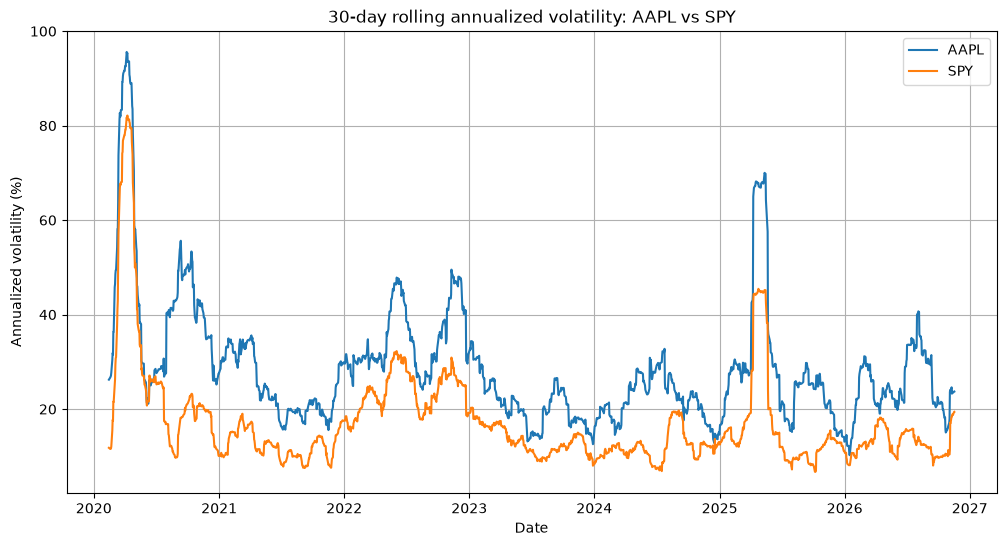

In [27]:
comparison["AAPL Rolling Volatility"] = (
    comparison["AAPL"].pct_change().rolling(30).std()
    * (252 ** 0.5) * 100
)

comparison["SPY Rolling Volatility"] = (
    comparison["SPY"].pct_change().rolling(30).std()
    * (252 ** 0.5) * 100
)

plt.figure(figsize=(12, 6))
plt.plot(
    comparison["Date"],
    comparison["AAPL Rolling Volatility"],
    label="AAPL"
)
plt.plot(
    comparison["Date"],
    comparison["SPY Rolling Volatility"],
    label="SPY"
)

plt.title("30-day rolling annualized volatility: AAPL vs SPY")
plt.xlabel("Date")
plt.ylabel("Annualized volatility (%)")
plt.legend()
plt.grid(True)
plt.show()

In [28]:
daily_returns = comparison[["AAPL", "SPY"]].pct_change().dropna()

correlation = daily_returns["AAPL"].corr(daily_returns["SPY"])

beta = (
    daily_returns["AAPL"].cov(daily_returns["SPY"])
    / daily_returns["SPY"].var()
)

print("AAPL-SPY correlation:", round(correlation, 3))
print("AAPL beta relative to SPY:", round(beta, 3))

AAPL-SPY correlation: 0.749
AAPL beta relative to SPY: 1.165


In [29]:
# Work out how many years the shared data covers
period_years = (
    comparison["Date"].iloc[-1] - comparison["Date"].iloc[0]
).days / 365.25

# Calculate daily returns
aapl_returns = comparison["AAPL"].pct_change().dropna()
spy_returns = comparison["SPY"].pct_change().dropna()

# Calculate drawdowns from each asset's previous peak
aapl_drawdown = comparison["AAPL"] / comparison["AAPL"].cummax() - 1
spy_drawdown = comparison["SPY"] / comparison["SPY"].cummax() - 1

# Calculate returns over the full period
aapl_total_return = (
    comparison["AAPL"].iloc[-1] / comparison["AAPL"].iloc[0] - 1
) * 100

spy_total_return = (
    comparison["SPY"].iloc[-1] / comparison["SPY"].iloc[0] - 1
) * 100

# Calculate annualized returns
aapl_annualized_return = (
    (comparison["AAPL"].iloc[-1] / comparison["AAPL"].iloc[0])
    ** (1 / period_years) - 1
) * 100

spy_annualized_return = (
    (comparison["SPY"].iloc[-1] / comparison["SPY"].iloc[0])
    ** (1 / period_years) - 1
) * 100

# Put the results together in one table
scorecard = pd.DataFrame({
    "Total return (%)": [aapl_total_return, spy_total_return],
    "Annualized return (%)": [
        aapl_annualized_return,
        spy_annualized_return
    ],
    "Annualized volatility (%)": [
        aapl_returns.std() * (252 ** 0.5) * 100,
        spy_returns.std() * (252 ** 0.5) * 100
    ],
    "Maximum drawdown (%)": [
        aapl_drawdown.min() * 100,
        spy_drawdown.min() * 100
    ]
}, index=["AAPL", "SPY"])

scorecard.round(2)

,Total return (%),Annualized return (%),Annualized volatility (%),Maximum drawdown (%)
AAPL,387.30,25.91,31.13,-33.36
SPY,147.96,14.12,20.02,-33.72


In [30]:
aapl_low_index = aapl_drawdown.idxmin()
spy_low_index = spy_drawdown.idxmin()

print(
    "AAPL maximum-drawdown trough:",
    comparison.loc[aapl_low_index, "Date"].date()
)
print(
    "SPY maximum-drawdown trough:",
    comparison.loc[spy_low_index, "Date"].date()
)

AAPL maximum-drawdown trough: 2025-04-08
SPY maximum-drawdown trough: 2020-03-23


In [31]:
daily_returns = comparison[["AAPL", "SPY"]].pct_change().dropna()

correlation = daily_returns["AAPL"].corr(daily_returns["SPY"])

beta = (
    daily_returns["AAPL"].cov(daily_returns["SPY"])
    / daily_returns["SPY"].var()
)

print("AAPL-SPY correlation:", round(correlation, 3))
print("AAPL beta relative to SPY:", round(beta, 3))

AAPL-SPY correlation: 0.749
AAPL beta relative to SPY: 1.165


In [32]:
# How long the shared data period covers
period_years = (
    comparison["Date"].iloc[-1] - comparison["Date"].iloc[0]
).days / 365.25

# Daily returns
daily_returns = comparison[["AAPL", "SPY"]].pct_change().dropna()

# Drawdowns from each asset's previous peak
aapl_drawdown = comparison["AAPL"] / comparison["AAPL"].cummax() - 1
spy_drawdown = comparison["SPY"] / comparison["SPY"].cummax() - 1

# Growth over the full shared period
aapl_growth = comparison["AAPL"].iloc[-1] / comparison["AAPL"].iloc[0]
spy_growth = comparison["SPY"].iloc[-1] / comparison["SPY"].iloc[0]

scorecard = pd.DataFrame({
    "Cumulative return (%)": [
        (aapl_growth - 1) * 100,
        (spy_growth - 1) * 100
    ],
    "Annualized return (%)": [
        (aapl_growth ** (1 / period_years) - 1) * 100,
        (spy_growth ** (1 / period_years) - 1) * 100
    ],
    "Annualized volatility (%)": [
        daily_returns["AAPL"].std() * (252 ** 0.5) * 100,
        daily_returns["SPY"].std() * (252 ** 0.5) * 100
    ],
    "Maximum drawdown (%)": [
        aapl_drawdown.min() * 100,
        spy_drawdown.min() * 100
    ]
}, index=["AAPL", "SPY"])

print("Shared period:", comparison["Date"].min().date(), "to",
      comparison["Date"].max().date())
scorecard.round(2)

Shared period: 2020-01-02 to 2026-11-17


,Cumulative return (%),Annualized return (%),Annualized volatility (%),Maximum drawdown (%)
AAPL,387.30,25.91,31.13,-33.36
SPY,147.96,14.12,20.02,-33.72


In [35]:
from pathlib import Path

Path("images").mkdir(exist_ok=True)
print("Images folder is ready.")

Images folder is ready.


In [36]:
plt.savefig("images/aapl-vs-spy-growth.png", dpi=200, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

In [37]:
plt.savefig("images/aapl-vs-spy-drawdown.png", dpi=200, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

In [38]:
plt.savefig("images/aapl-vs-spy-rolling-volatility.png", dpi=200, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

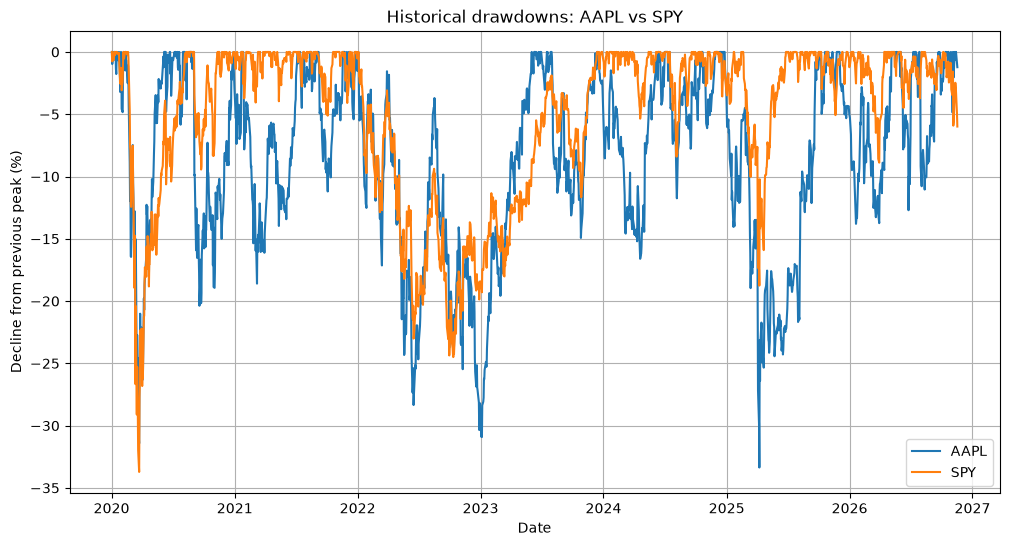

In [39]:
from pathlib import Path
import matplotlib.pyplot as plt

Path("images").mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(comparison["Date"], aapl_drawdown * 100, label="AAPL")
ax.plot(comparison["Date"], spy_drawdown * 100, label="SPY")

ax.set_title("Historical drawdowns: AAPL vs SPY")
ax.set_xlabel("Date")
ax.set_ylabel("Decline from previous peak (%)")
ax.legend()
ax.grid(True)

fig.savefig(
    "images/aapl-vs-spy-drawdown.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

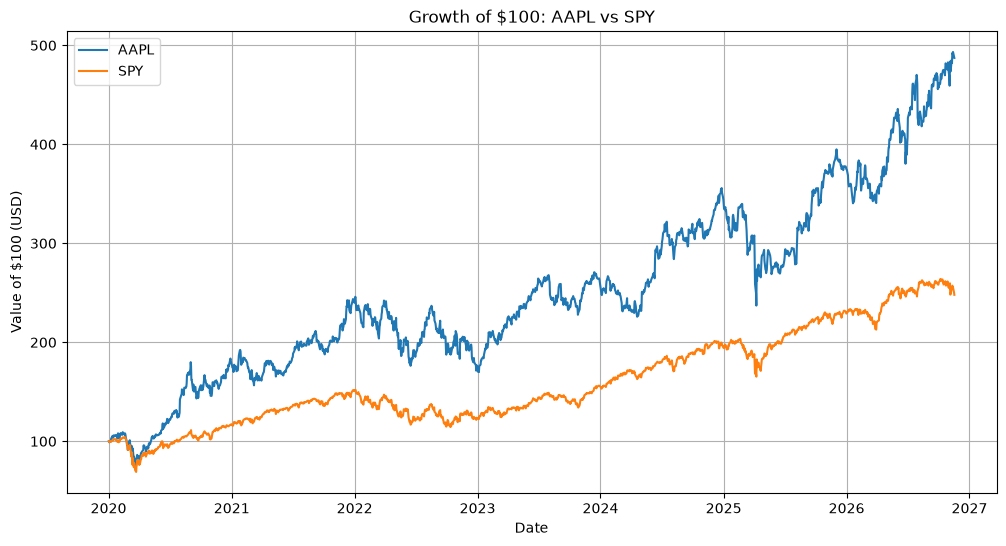

In [40]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(comparison["Date"], comparison["AAPL Growth of $100"], label="AAPL")
ax.plot(comparison["Date"], comparison["SPY Growth of $100"], label="SPY")

ax.set_title("Growth of $100: AAPL vs SPY")
ax.set_xlabel("Date")
ax.set_ylabel("Value of $100 (USD)")
ax.legend()
ax.grid(True)

fig.savefig("images/aapl-vs-spy-growth.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

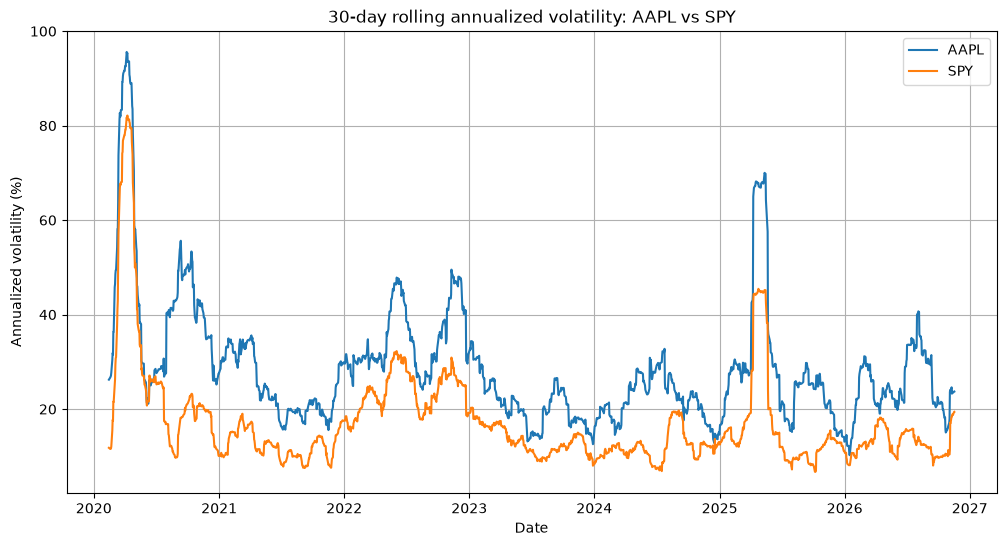

In [41]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(
    comparison["Date"],
    comparison["AAPL Rolling Volatility"],
    label="AAPL"
)
ax.plot(
    comparison["Date"],
    comparison["SPY Rolling Volatility"],
    label="SPY"
)

ax.set_title("30-day rolling annualized volatility: AAPL vs SPY")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized volatility (%)")
ax.legend()
ax.grid(True)

fig.savefig(
    "images/aapl-vs-spy-rolling-volatility.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

In [42]:
from pathlib import Path
import matplotlib.pyplot as plt

Path("images").mkdir(exist_ok=True)

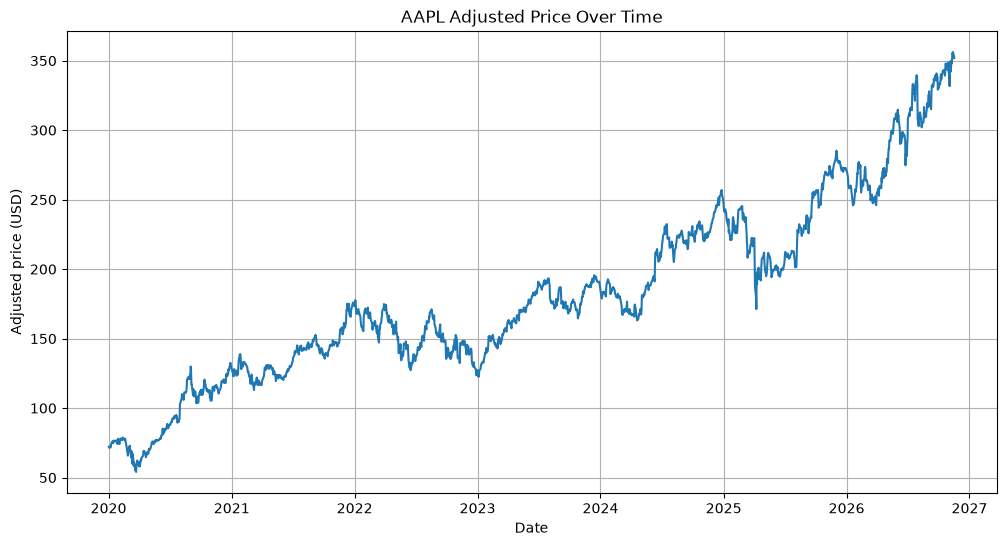

In [43]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(prices["Date"], prices["Adj Close"])
ax.set_title("AAPL Adjusted Price Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Adjusted price (USD)")
ax.grid(True)

fig.savefig(
    "images/aapl-adjusted-price.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

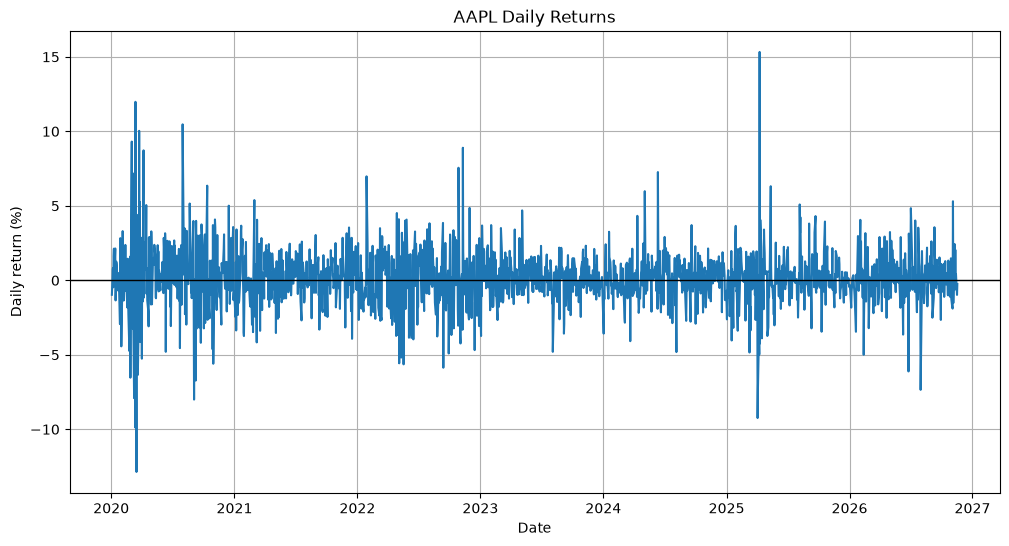

In [44]:
daily_returns = prices["Adj Close"].pct_change() * 100

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(prices["Date"], daily_returns)
ax.set_title("AAPL Daily Returns")
ax.set_xlabel("Date")
ax.set_ylabel("Daily return (%)")
ax.axhline(0, color="black", linewidth=1)
ax.grid(True)

fig.savefig(
    "images/aapl-daily-returns.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)